
# Pointwise power residual in the kernel of the scattering dual

Bound on the scattered power $\tfrac12 I^H R_0 I$ of a structure carved out of the copper 2:1 plate (`*_patch21ka1.txt`, $ka = 1$ at 2.45 GHz,
plane wave $E_0 = 1$ kV/m), in the RWG basis with $Z_\mathrm{mat} = Z_s L$ and the scattered voltage $x = V_\mathrm{sca} = -Z_0 I$ as the
variable, as in `nullspaceSparsity.ipynb`. The GCD Lagrangian $L^\star$ is (nearly) constant on $x = x_r + N y$, with $N$ its near-kernel at
$\epsilon = 10^{-4}$ (about 0.5 % of the Lagrangian, below the mesh precision) and $x_r = (1 - N N^H) x^\star$.

**Metric.** The pointwise complex power of basis function $i$,
$$w_i = \overline{I_i}\, r_i, \qquad r = V - Z_\mathrm{tot} I ,$$
vanishes exactly for void ($I_i = 0$) or metal ($r_i = 0$, $d_i = 1$). A passive relaxed density has the series impedance
$z_i = r_i / I_i = Z_s L_{ii}(1/d_i - 1)$, so $w_i = |I_i|^2 z_i$ lies on the ray of $Z_s$ ($45°$). Its component off that ray,
$q_i = \operatorname{Im}(e^{-j\pi/4} w_i)$, is the reactive load that `nullspaceSparsity.ipynb` found: the complementarity current lay on the
reactive-load circle of the complex density. The kernel component minimizes a smoothed count of non-binary and of reactive edges,
$$\min_y \; \sum_i \log\big(|w_i(y)|^2 + \delta^2\big) + \gamma \sum_i \log\big(q_i(y)^2 + \delta^2\big)
\quad \text{s.t. the global power constraints } (p = 1, p = j),$$
for $\gamma = 0$ (binary count only) and $\gamma = 10$ (reactive loads penalized).

**Void current.** A small density $d_i$ only says $|r_i| \gg |Z_s L_{ii} I_i|$, so an edge at $d \approx 0$ can still carry current through a large
series impedance. Starting from the $\gamma = 10$ result, every edge that has settled at $|d_i| < 0.05$ therefore counts $\log(|I_i|^2 + \delta_I^2)$
instead of its $w_i$ terms. The current is affine in $y$, so no linearization is needed. The void set is fixed at the start of this phase. The
smoothing of $w$ stays at its final value, so the metal pattern is kept, while $\delta_I$ decreases from $0.3$ of the rms current, and every
step must decrease the smoothed count.

**Gauss–Newton IRLS.** The current and the residual are affine in $y$: $I = a + B y$ and $r = b + C y$. Hence $w_i$ is quadratic in $y$, and it is
linearized at the iterate as $w_i \approx \overline{I^k_i} r_i(y) + \overline{I_i(y)} r^k_i - \overline{I^k_i} r^k_i$. This linearization contains $\bar y$, so
each step is a real least-squares problem in $z = (\operatorname{Re} y, \operatorname{Im} y)$:
- the weights are $1/(|w^k_i|^2 + \delta^2)$ and $\gamma/(q^{k\,2}_i + \delta^2)$, plus a Levenberg–Marquardt damping $\mu |z - z^k|^2$;
- the global power constraints are written in $z$;
- the QCQP is solved by `DenseSharedProjQCQP` with real data, so its dual current is real.

$\delta$ is relative to the rms of $w$ at the GCD solution and decreases geometrically. A step whose smoothed count increases is rejected
and the damping raised (at most to $\mu = 10^2$; if no step is accepted, the iterate is kept).

**Classification.** A basis function counts as metal for $|d_i - 1| < 0.05$ and as void for $|I_i| < 0.01 \max|I|$ (a small $|d_i|$ alone only means
$|r_i| \gg |Z_s L_{ii} I_i|$, which already holds for the GCD current everywhere).

**Counting.** Driving all $w_i$ to zero needs $2 \times 233$ real equations, while the kernel has $2K - 2 \approx 320$ real degrees of freedom. The
metric can make most, not all, basis functions binary.


In [1]:
import contextlib
import copy
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.linalg as la
import scipy.sparse as sp
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LogNorm
from scipy.optimize import least_squares

from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
matrixSet = "patch21ka1" # copper 2:1 plate, ka = 1; omW and the mesh exist for this set only (exportOmWpatch21ka1.m)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum
eta_0 = np.sqrt(mu_0/epsilon_0) # free-space impedance

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
omega = 2 * np.pi * frequency # angular frequency

copper_conductivity = 5.96e7 # S/m
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta) # surface impedance
print(f"Surface impedance: {Zs} Ω")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω


In [3]:
def Msym(M):
    return(0.5*(M.conj().T + M))

# Load matrices from text files (original RWG basis, no Cholesky transformation)
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix
R0 = Msym(np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',')) # radiated power matrix
X0 = Msym(np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',')) # reactive power matrix
Vinc = E0*np.loadtxt(f"V_{matrixSet}.txt", delimiter=',').astype(complex) # voltage excitation vector

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Zmat = Zs * Lmat # material impedance matrix (non-diagonal)
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix
Ldiag = np.diag(Lmat).copy() # diagonal of the lossy matrix

def evalObj(Ivec):
    # scattered (radiated) power
    return(0.5*np.real(Ivec.conj() @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc)
Pfull = evalObj(Ifull)
print(f"Objective for full plate: {Pfull:.6e} W")

# reference: lossless resonant electric dipole, sigma_sca = 3 lambda^2 / (2 pi)
Pdip = 3*(c/frequency)**2/(2*np.pi) * E0**2/(2*eta_0)
print(f"resonant dipole scattered power: {Pdip:.4f} W")

Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W
resonant dipole scattered power: 9.4884 W


In [4]:
# mesh of the operators (exportOmWpatch21ka1.m): bf[n] = [T+, T-, edge node 1, edge node 2], 0 based
mesh = sio.loadmat(f"mesh_{matrixSet}.mat")
nodes, tria, bf = mesh["nodes"], mesh["triangles"], mesh["bf"]
edgeLen = np.linalg.norm(nodes[bf[:, 2]] - nodes[bf[:, 3]], axis=1)
e1, e2 = nodes[tria[:, 1]] - nodes[tria[:, 0]], nodes[tria[:, 2]] - nodes[tria[:, 0]]
triArea = 0.5*np.abs(e1[:, 0]*e2[:, 1] - e1[:, 1]*e2[:, 0])
triCent = nodes[tria].mean(axis=1)
freeNode = np.array([[np.setdiff1d(tria[t], bf[n, 2:])[0] for t in bf[n, :2]] for n in range(Ndes)]) # free vertices of T+, T-
print(f"{len(nodes)} nodes, {len(tria)} triangles, plate {np.ptp(nodes[:, 0])*1e3:.2f} x {np.ptp(nodes[:, 1])*1e3:.2f} mm, "
      f"Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error {np.max(np.abs(Ldiag/(5/(6*np.sqrt(3))*edgeLen**2) - 1)):.1e}")

def currentDensity(I):
    # RWG current density at the triangle centroids, J = I_n l_n rho / (2 A)
    J = np.zeros((len(tria), 2), dtype=complex)
    for s, sgn in [(0, 1), (1, -1)]:
        rho = sgn*(triCent[bf[:, s]] - nodes[freeNode[:, s]])
        np.add.at(J, bf[:, s], (I*edgeLen/(2*triArea[bf[:, s]]))[:, None]*rho)
    return J

def plotStructure(ax, keep, I, title=""):
    # metal triangles colored by |J| (log); removed RWG functions between metal triangles are slots (red), void triangles white
    metal = np.zeros(len(tria), dtype=bool)
    metal[bf[keep, :2].ravel()] = True
    J = np.linalg.norm(np.abs(currentDensity(I)), axis=1)
    pc = PolyCollection(nodes[tria[metal]], array=np.maximum(J[metal], 1e-3*J.max()), cmap='viridis',
                        norm=LogNorm(1e-3*J.max(), J.max()), edgecolors='none')
    ax.add_collection(pc)
    ax.add_collection(PolyCollection(nodes[tria[~metal]], facecolors='white', edgecolors='0.85', linewidths=0.3))
    slot = ~keep & metal[bf[:, 0]] & metal[bf[:, 1]]
    ax.add_collection(LineCollection(nodes[bf[slot, 2:]], colors='r', linewidths=1.5))
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return pc

def plotDensity(ax, d, title=""):
    # inferred density on the RWG edges
    lc = LineCollection(nodes[bf[:, 2:]], array=np.log10(np.maximum(d, 1e-6)), cmap='viridis', linewidths=2.5)
    lc.set_clim(-6, 0)
    ax.add_collection(lc)
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return lc

def plotComplexDensity(axes, d, title=""):
    # complex density on the RWG edges: Re d (1 metal, 0 void) and Im d (0 for any structure), on a common symmetric scale
    dmax = np.quantile(np.abs(d), 0.99)
    for ax, part, name in [(axes[0], d.real, "Re d"), (axes[1], d.imag, "Im d")]:
        lc = LineCollection(nodes[bf[:, 2:]], array=part, cmap='RdBu_r', linewidths=2.5)
        lc.set_clim(-dmax, dmax)
        ax.add_collection(lc)
        ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
        ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{title}: {name}, scale \u00b1{dmax:.1e}", fontsize=8)
        plt.colorbar(lc, ax=ax, shrink=0.8, format='%.0e')
    return lc

104 nodes, 168 triangles, plate 35.05 x 17.00 mm, Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error 2.6e-14


## Scattering QCQP, global and GCD bounds

As in `maxScatFixQ.ipynb`: $A_0 = -\tfrac12 W^H R_0 W$ with $W = Z_0^{-1}$, $I = -W x$, and the projector constraints
$\operatorname{Re}(-x^H A_1 P A_2 x + 2 x^H A_2^H P^H s_1) = 0$ with $A_1 = 1 + W^H Z_\mathrm{mat}^H$, $A_2 = W$, $s_1 = -\tfrac12 V$, i.e.
$\operatorname{Re}\sum_i p_i^* w_i = 0$, $w_i = I_i^*(V - Z_\mathrm{tot} I)_i$. The global bound uses $p = \mathbf 1$ and $p = j\mathbf 1$; GCD adds
two diagonal projectors per iteration (20 iterations, no merging). GCD is slightly non-deterministic (ARPACK starts and the random
`Pstruct` coefficients).

In [5]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0) # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0
A1 = np.eye(Ndes) + WH @ Zmat.conj().T
A2 = W
s1 = -0.5 * Vinc

def VtoI(Vsca):
    return(-W @ Vsca)

def localViolation(I):
    # pointwise w_i = I_i^* (V - Ztot I)_i, zero for any structure made of enabled basis functions
    return(np.conj(I)*(Vinc - Ztot @ I))

def constraintRes(Q, x):
    # c_k(x) = Re(-x^H A_k x + 2 x^H F_k) + c_k for all constraints (W), zero for a feasible x
    res = np.real(-x.conj() @ Q._allA_at_v(x) + 2*x.conj() @ Q.Fs)
    res[Q.n_proj_constr:] += Q.c_2j
    return res

def lagSpectrum(Q):
    return np.linalg.eigvalsh(Msym(Q._get_total_A(Q.current_lags)))

opt_params = OptimizationHyperparameters(opttol=1e-8,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=20,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

np.random.seed(0)
PlistGlob = [sp.diags(q*np.ones(Ndes, dtype=complex)) for q in [1, 1j]] # global real and reactive power
Qglob = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistGlob, A2=A2, verbose=0)
Qglob.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0]), opt_params=opt_params)

Ngcd = 20 # number of GCD iterations
Qgcd = copy.deepcopy(Qglob)
gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd,
    max_gcd_iter_num=Ngcd,
    gcd_iter_period=Ngcd + 1, # no early termination
    opt_params=opt_params)
t1 = time.time()
with contextlib.redirect_stdout(io.StringIO()): # silence the per-iteration GCD output
    Qgcd.run_gcd(gcd_params)
print(f"GCD: {time.time() - t1:.1f}s")

for name, Q in [("global", Qglob), (f"GCD {Ngcd}", Qgcd)]:
    lam = lagSpectrum(Q)
    I = VtoI(Q.current_xstar)
    print(f"{name}: D {Q.current_dual:.6e} W ({Q.current_dual/Pdip:.2f} x resonant dipole), {Q.n_proj_constr} constraints, "
          f"min/max eig L* {lam[0]/lam[-1]:.1e}, ||c(x*)||/D {np.linalg.norm(constraintRes(Q, Q.current_xstar))/Q.current_dual:.1e}, "
          f"max|w_i|/|I^H V| {np.abs(localViolation(I)).max()/np.abs(I.conj() @ Vinc):.1e}")

cond(Z0) = 6.327e+02


GCD: 35.3s
global: D 1.847944e+01 W (1.95 x resonant dipole), 2 constraints, min/max eig L* 8.7e-06, ||c(x*)||/D 2.3e-04, max|w_i|/|I^H V| 4.0e+01
GCD 20: D 1.774049e+01 W (1.87 x resonant dipole), 42 constraints, min/max eig L* 8.2e-14, ||c(x*)||/D 6.9e-03, max|w_i|/|I^H V| 3.6e+01


## Image and kernel

The near-kernel $N$ of the GCD $L^\star$ at $\epsilon = 10^{-4}$, and the change of the Lagrangian when the kernel component of $x^\star$ is replaced.

eps 1e-04: kernel dimension 162 of 233, largest kernel eigenvalue / max 9.6e-05, next 1.0e-04


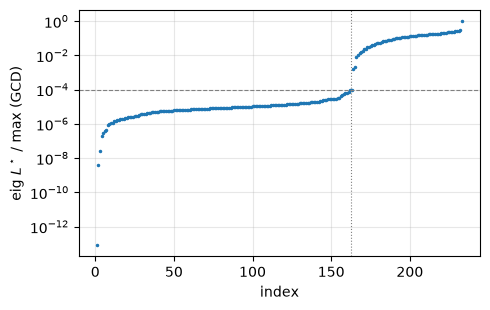

In [6]:
kerTol = 1e-4
lamGCD, UGCD = np.linalg.eigh(Msym(Qgcd._get_total_A(Qgcd.current_lags)))
N = UGCD[:, lamGCD < kerTol*lamGCD[-1]]
K = N.shape[1]
xs = Qgcd.current_xstar
xr = xs - N @ (N.conj().T @ xs)
print(f"eps {kerTol:.0e}: kernel dimension {K} of {Ndes}, largest kernel eigenvalue / max {lamGCD[K - 1]/lamGCD[-1]:.1e}, "
      f"next {lamGCD[K]/lamGCD[-1]:.1e}")

def lagrangianRatio(x):
    # scattering Lagrangian D - (x - x*)^H L* (x - x*), relative to D
    e = x - xs
    return 1 - np.real(e.conj() @ Msym(Qgcd._get_total_A(Qgcd.current_lags)) @ e)/Qgcd.current_dual

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(np.arange(1, Ndes + 1), lamGCD/lamGCD[-1], '.', ms=3)
ax.axhline(kerTol, ls='--', c='gray', lw=0.8); ax.axvline(K + 0.5, ls=':', c='gray', lw=0.8)
ax.set_xlabel('index'); ax.set_ylabel(r'eig $L^\star$ / max (GCD)'); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Gauss–Newton IRLS on the power residual

In [7]:
def shiftForm(A, s, c, x0, N):
    # f(x0 + N y) in the same form, in y
    Ax0 = A @ x0
    return Msym(N.conj().T @ A @ N), N.conj().T @ (s - Ax0), float(np.real(-x0.conj() @ Ax0 + 2*x0.conj() @ s) + c)

def generalQCQP(objective, cons):
    # QCQP with only general constraints (A2 = 1), objective (A0, s0, c0) and constraints [(B_j, s_2j, c_2j)]
    A0r, s0r, c0r = objective
    K = len(s0r)
    return DenseSharedProjQCQP(A0r, s0r, c0r, np.eye(K, dtype=complex), np.zeros(K, dtype=complex), [], Pstruct=sp.eye(K),
                               B_j=[c[0] for c in cons], s_2j=[c[1] for c in cons], c_2j=np.array([c[2] for c in cons]), verbose=0)

def setLags(Q, lags):
    Q.current_lags = lags
    Q.current_dual = Q.get_dual(lags)[0]
    Q.current_xstar = Q._get_xstar(lags)[0]

class EvalCap(Exception):
    pass

def solveReduced(Qr, lags, maxEval=3000):
    # start from (1 + t) lags, the smallest |t| in the list that is strictly dual feasible (t < 0 shrinks toward lambda = 0, feasible for A0 > 0). The optimizer has no iteration limit and a
    # reduced dual can be unbounded below (infeasible restricted primal, see Kernel GCD), so get_dual is capped at maxEval calls and
    # the multipliers with the lowest unpenalized dual seen are kept. Returns t and whether the cap was hit.
    t = next(t for t in [1e-6, -1e-6, 1e-4, -1e-4, 1e-2, -1e-2, 0.1, -0.1, 1.0, -0.5, 10.0, -1.0] if Qr.is_dual_feasible((1 + t)*lags))
    l0 = (1 + t)*lags
    best = [Qr.get_dual(l0)[0], l0.copy()]
    count = [0]
    getDual = Qr.get_dual
    def cappedDual(l, *args, **kwargs):
        count[0] += 1
        if count[0] > maxEval:
            raise EvalCap
        out = getDual(l, *args, **kwargs)
        D = out[0] if not kwargs.get("penalty_vectors") else getDual(l)[0]
        if D < best[0]:
            best[0], best[1] = D, np.array(l, dtype=float).copy()
        return out
    Qr.get_dual = cappedDual
    capped = False
    try:
        Qr.solve_current_dual_problem(method='newton', init_lags=l0, opt_params=opt_params)
    except EvalCap:
        capped = True
    finally:
        del Qr.get_dual
    if capped or Qr.current_dual > best[0]:
        setLags(Qr, best[1])
    return t, capped

def projectorForm(p, a, B):
    # diagonal projector constraint Re(-x^H A1 P A2 x + 2 x^H A2^H P^H s1) at x = a + B y, as a general constraint in y
    return shiftForm(Msym(A1 @ (p[:, None]*A2)), A2.conj().T @ (np.conj(p)*s1), 0.0, a, B)

In [8]:
Wn = W @ N
a, B = -W @ xr, -Wn # I = a + B y
b, Cm = Vinc + Ztot @ (W @ xr), Ztot @ Wn # r = b + C y
rot = np.exp(-1j*np.pi/4) # q = Im(rot w), the component off the passive ray of Zs

def realify(B2, s2, c2):
    # -y^H B y + 2 Re(y^H s) + c with y = u + j v, as a real quadratic in z = (u, v)
    Br, Bi = B2.real, B2.imag
    return (np.block([[Br, -Bi], [Bi, Br]]).astype(complex), np.r_[s2.real, s2.imag].astype(complex), c2)

consGlobZ = [realify(*projectorForm(p, xr, N)) for p in [np.ones(Ndes, dtype=complex), 1j*np.ones(Ndes, dtype=complex)]]

def toY(z):
    return z[:K] + 1j*z[K:]

def powerRes(y):
    I, r = a + B @ y, b + Cm @ y
    return I, r, np.conj(I)*r

def linearization(y):
    # w(y + dy) = w + conj(I) C dy + r conj(B dy) + O(dy^2), as real Jacobians of (Re w, Im w) and of q w.r.t. z = (Re dy, Im dy)
    I, r, w = powerRes(y)
    P1 = np.conj(I)[:, None]*Cm # holomorphic part
    P2 = r[:, None]*np.conj(B)  # antiholomorphic part, multiplies conj(dy)
    Jc = np.hstack([P1 + P2, 1j*(P1 - P2)]) # d w / d(u, v)
    return w, Jc

def merit(w, delta, gamma):
    return np.sum(np.log(np.abs(w)**2 + delta**2)) + gamma*np.sum(np.log((rot*w).imag**2 + delta**2))

def meritV(y, delta, gamma, void=None, deltaI=None):
    # smoothed count of non-binary edges; on the void set the current itself is counted
    I, r, w = powerRes(y)
    if void is None:
        return merit(w, delta, gamma)
    return merit(w[~void], delta, gamma) + np.sum(np.log(np.abs(I[void])**2 + deltaI**2))

def gnStep(y, delta, gamma, mu, lags, void=None, deltaI=None):
    # weighted least squares in z for the linearized residuals, with LM damping, under the global constraints
    w, Jc = linearization(y)
    z0 = np.r_[y.real, y.imag]
    keep = np.ones(Ndes, dtype=bool) if void is None else ~void
    w, Jc = w[keep], Jc[keep]
    rows = [np.vstack([Jc.real, Jc.imag]), (rot*Jc).imag]
    res0 = [np.r_[w.real, w.imag], (rot*w).imag]
    om = [np.tile(1/(np.abs(w)**2 + delta**2), 2), gamma/((rot*w).imag**2 + delta**2)]
    if void is not None and void.any():
        I = a + B @ y
        JI = np.hstack([B, 1j*B])[void] # d I / d(u, v), exact
        rows.append(np.vstack([JI.real, JI.imag]))
        res0.append(np.r_[I[void].real, I[void].imag])
        om.append(np.tile(1/(np.abs(I[void])**2 + deltaI**2), 2))
    H = sum((J.T*o) @ J for J, o in zip(rows, om) if np.any(o))
    g = sum((J.T*o) @ (rr - J @ z0) for J, rr, o in zip(rows, res0, om) if np.any(o))
    c = sum(np.sum(o*(rr - J @ z0)**2) for J, rr, o in zip(rows, res0, om) if np.any(o))
    damp = mu*np.trace(H)/len(z0)
    H = H + damp*np.eye(len(z0)); g = g - damp*z0; c = c + damp*z0 @ z0
    scale = z0 @ H @ z0 + 2*g @ z0 + c # objective at the iterate
    Q = generalQCQP(((H/scale).astype(complex), (-g/scale).astype(complex), -c/scale), consGlobZ)
    t, capped = solveReduced(Q, lags)
    z = Q.current_xstar
    return toY(z.real), Q.current_lags.copy(), np.linalg.norm(z.imag)/np.linalg.norm(z), capped

# check: the linearization at the GCD solution against a finite difference
y0 = N.conj().T @ (xs - xr)
w0, J0 = linearization(y0)
rng = np.random.default_rng(0)
dz = 1e-6*np.linalg.norm(y0)*rng.standard_normal(2*K)
w1 = powerRes(y0 + toY(dz))[2]
print(f"linearization check: |w(y + dy) - w - J dz| / |w(y + dy) - w| = {np.linalg.norm(w1 - w0 - J0 @ dz)/np.linalg.norm(w1 - w0):.1e}")

linearization check: |w(y + dy) - w - J dz| / |w(y + dy) - w| = 2.0e-06


In [9]:
def kernelStats(y):
    x = xr + N @ y
    I, r, w = powerRes(y)
    d = complexDensity(I)
    return dict(P=evalObj(I)/Qgcd.current_dual, Lag=lagrangianRatio(x),
                cGlob=np.linalg.norm(constraintRes(Qglob, x))/Qgcd.current_dual,
                void=int(np.count_nonzero(np.abs(I) < 1e-2*np.abs(I).max())), metal=int(np.count_nonzero(np.abs(d - 1) < 0.05)),
                wSum=np.sum(np.abs(w))/np.abs(I.conj() @ Vinc), reactive=np.sum(np.abs((rot*w).imag))/np.sum(np.abs(w)))

def complexDensity(I):
    u = Vinc - Ztot @ I + Zs*Ldiag*I
    return Zs*Ldiag*I/u

def powerResIRLS(gamma, nIter=40, delta0=1.0, deltaMin=1e-4, rate=0.75, mu0=1e-3, muMax=1e2):
    y = N.conj().T @ (xs - xr) # start at the GCD dual current
    sw = np.sqrt(np.mean(np.abs(powerRes(y)[2])**2))
    lags, mu, hist = np.zeros(2), mu0, [dict(it=0, mu=np.nan, delta=np.nan, accepted=True, **kernelStats(y))]
    for it in range(1, nIter + 1):
        delta = max(delta0*rate**(it - 1), deltaMin)*sw
        m0 = merit(powerRes(y)[2], delta, gamma)
        for attempt in range(6):
            yn, lagsn, imagRel, capped = gnStep(y, delta, gamma, mu, lags)
            # the first step only restores the power balance, later steps must not increase the smoothed count
            if np.all(np.isfinite(yn)) and (it == 1 or merit(powerRes(yn)[2], delta, gamma) <= m0 + 1e-9*abs(m0)):
                y, lags, mu = yn, lagsn, max(mu/3, 1e-6)
                break
            mu = min(10*mu, muMax)
        else:
            hist.append(dict(it=it, mu=mu, delta=delta/sw, accepted=False, **kernelStats(y)))
            mu = mu0 # the step is skipped, delta still decreases
            continue
        hist.append(dict(it=it, mu=mu, delta=delta/sw, accepted=True, imag=imagRel, capped=capped, **kernelStats(y)))
    return xr + N @ y, hist

def voidIRLS(x0, gamma, nIter=40, fW=1e-4, delta0=0.3, deltaMin=1e-4, rate=0.75, mu0=1e-3, muMax=1e2, dVoid=0.05):
    # continue from x0: edges settled at |d| < dVoid count |I_i| instead of |w_i| (void set fixed at the start). The smoothing of w stays
    # at its final value fW (the metal pattern is kept), the smoothing of the void currents decreases from delta0
    y = N.conj().T @ (x0 - xr)
    I0, r0, w0 = powerRes(y)
    sw, sI = np.sqrt(np.mean(np.abs(w0)**2)), np.sqrt(np.mean(np.abs(I0)**2))
    void = np.abs(complexDensity(I0)) < dVoid
    lags, mu, hist = np.zeros(2), mu0, [dict(it=0, mu=np.nan, delta=np.nan, accepted=True, voidSet=int(void.sum()), **kernelStats(y))]
    for it in range(1, nIter + 1):
        f = max(delta0*rate**(it - 1), deltaMin)
        delta, deltaI = fW*sw, f*sI
        m0 = meritV(y, delta, gamma, void, deltaI)
        for attempt in range(6):
            yn, lagsn, imagRel, capped = gnStep(y, delta, gamma, mu, lags, void, deltaI)
            if np.all(np.isfinite(yn)) and meritV(yn, delta, gamma, void, deltaI) <= m0 + 1e-9*abs(m0):
                y, lags, mu = yn, lagsn, max(mu/3, 1e-6)
                break
            mu = min(10*mu, muMax)
        else:
            hist.append(dict(it=it, mu=mu, delta=f, accepted=False, voidSet=int(void.sum()), **kernelStats(y)))
            mu = mu0
            continue
        hist.append(dict(it=it, mu=mu, delta=f, accepted=True, imag=imagRel, capped=capped, voidSet=int(void.sum()), **kernelStats(y)))
    return xr + N @ y, hist

def irlsReport(name, hist):
    print(name)
    for h in hist:
        step = "" if h["it"] == 0 else f"delta {h['delta']:.1e}, mu {h['mu']:.0e}{'' if h['accepted'] else ' (rejected)'}, "
        print(f"  it {h['it']:2d}: {step}P/D {h['P']:.4f}, Lagrangian/D {h['Lag']:.4f}, ||c_global||/D {h['cGlob']:.1e}, "
              f"void {h['void']:3d}, metal {h['metal']:3d}, sum|w|/|I^H V| {h['wSum']:.2e}, reactive fraction {h['reactive']:.2f}"
              + (f", void set {h['voidSet']:3d}" if "voidSet" in h else ""))

results = {}
for gamma in [0.0, 10.0]:
    t1 = time.time()
    results[f"gamma {gamma:g}"] = powerResIRLS(gamma)
    irlsReport(f"gamma {gamma:g} ({time.time() - t1:.0f}s)", results[f"gamma {gamma:g}"][1])

# void-current phase, continued from the gamma = 10 result
t1 = time.time()
results["gamma 10 + void current"] = voidIRLS(results["gamma 10"][0], 10.0)
irlsReport(f"gamma 10 + void current ({time.time() - t1:.0f}s)", results["gamma 10 + void current"][1])

gamma 0 (55s)
  it  0: P/D 1.0000, Lagrangian/D 1.0000, ||c_global||/D 2.7e+02, void   5, metal   0, sum|w|/|I^H V| 8.50e+02, reactive fraction 0.68
  it  1: delta 1.0e+00, mu 3e-04, P/D 0.9990, Lagrangian/D 0.9559, ||c_global||/D 9.9e-05, void   2, metal   0, sum|w|/|I^H V| 5.37e+02, reactive fraction 0.63
  it  2: delta 7.5e-01, mu 1e-04, P/D 0.9992, Lagrangian/D 0.9705, ||c_global||/D 1.2e+02, void   4, metal   0, sum|w|/|I^H V| 4.07e+02, reactive fraction 0.69
  it  3: delta 5.6e-01, mu 1e+02 (rejected), P/D 0.9992, Lagrangian/D 0.9705, ||c_global||/D 1.2e+02, void   4, metal   0, sum|w|/|I^H V| 4.07e+02, reactive fraction 0.69
  it  4: delta 4.2e-01, mu 3e-04, P/D 0.9989, Lagrangian/D 0.9700, ||c_global||/D 1.1e+02, void   6, metal   0, sum|w|/|I^H V| 4.03e+02, reactive fraction 0.70
  it  5: delta 3.2e-01, mu 1e+02 (rejected), P/D 0.9989, Lagrangian/D 0.9700, ||c_global||/D 1.1e+02, void   6, metal   0, sum|w|/|I^H V| 4.03e+02, reactive fraction 0.70
  it  6: delta 2.4e-01, mu 3e

gamma 10 (24s)
  it  0: P/D 1.0000, Lagrangian/D 1.0000, ||c_global||/D 2.7e+02, void   5, metal   0, sum|w|/|I^H V| 8.50e+02, reactive fraction 0.68
  it  1: delta 1.0e+00, mu 3e-04, P/D 0.9983, Lagrangian/D 0.9644, ||c_global||/D 5.6e-05, void   4, metal   0, sum|w|/|I^H V| 6.06e+02, reactive fraction 0.39
  it  2: delta 7.5e-01, mu 1e-04, P/D 0.9989, Lagrangian/D 0.9839, ||c_global||/D 1.1e+02, void   2, metal   0, sum|w|/|I^H V| 4.83e+02, reactive fraction 0.32
  it  3: delta 5.6e-01, mu 4e-04, P/D 0.9986, Lagrangian/D 0.9899, ||c_global||/D 7.0e+01, void   0, metal   0, sum|w|/|I^H V| 4.24e+02, reactive fraction 0.28
  it  4: delta 4.2e-01, mu 1e-04, P/D 0.9983, Lagrangian/D 0.9832, ||c_global||/D 1.4e-05, void   1, metal   0, sum|w|/|I^H V| 4.39e+02, reactive fraction 0.23
  it  5: delta 3.2e-01, mu 4e-05, P/D 0.9991, Lagrangian/D 0.9883, ||c_global||/D 5.2e-06, void   1, metal   0, sum|w|/|I^H V| 4.31e+02, reactive fraction 0.19
  it  6: delta 2.4e-01, mu 1e-05, P/D 0.9987, Lagr

gamma 10 + void current (91s)
  it  0: P/D 0.9984, Lagrangian/D 0.9872, ||c_global||/D 5.5e-04, void   7, metal 105, sum|w|/|I^H V| 4.99e+02, reactive fraction 0.07, void set 118
  it  1: delta 3.0e-01, mu 3e-04, P/D 0.9984, Lagrangian/D 0.9872, ||c_global||/D 1.2e-05, void   7, metal 114, sum|w|/|I^H V| 4.99e+02, reactive fraction 0.07, void set 118
  it  2: delta 2.2e-01, mu 1e-04, P/D 0.9984, Lagrangian/D 0.9872, ||c_global||/D 2.4e-04, void   7, metal 114, sum|w|/|I^H V| 4.99e+02, reactive fraction 0.07, void set 118
  it  3: delta 1.7e-01, mu 4e-05, P/D 0.9984, Lagrangian/D 0.9872, ||c_global||/D 6.4e-05, void   7, metal 115, sum|w|/|I^H V| 4.99e+02, reactive fraction 0.07, void set 118
  it  4: delta 1.3e-01, mu 1e-05, P/D 0.9984, Lagrangian/D 0.9872, ||c_global||/D 1.1e-05, void   7, metal 115, sum|w|/|I^H V| 4.99e+02, reactive fraction 0.07, void set 118
  it  5: delta 9.5e-02, mu 4e-06, P/D 0.9984, Lagrangian/D 0.9872, ||c_global||/D 1.3e-05, void   7, metal 115, sum|w|/|I^H V

## Releasing the image part: full space with a Lagrangian penalty

In the kernel at most about $K$ basis functions can be binary. Here the whole $x$ moves. The cost in scattering is controlled by the Lagrangian
distance to the GCD optimum,
$$J(x) = (x - x^\star)^H L^\star (x - x^\star), \qquad f_0(x) + \sum_k \lambda^\star_k c_k(x) = D - J(x),$$
so for a structure, where all pointwise constraints hold, the scattered power is $P = D - J - \sum_k \lambda^\star_k c_k$, and $J$ is what the design
gives up. The full-space Gauss–Newton IRLS minimizes
$$\sum_{i \notin \mathcal V} \log(|w_i|^2 + \delta_w^2) + \gamma \sum_{i \notin \mathcal V} \log(q_i^2 + \delta_w^2) + \sum_{i \in \mathcal V} \log(|I_i|^2 + \delta_I^2) + \kappa\, J(x)/D$$
under the global power constraints. The real degrees of freedom are now $2N - 2 = 464$, enough for every basis function to be binary.
- **Start and void set.** It starts from the kernel result with $\gamma = 10$ and the void phase. The void set $\mathcal V$ (edges with $|d_i| < 0.05$ there) is
  fixed.
- **Smoothing.** $\delta_w$ stays at its final value, and $\delta_I$ decreases from 0.3 of the rms current.
- **Penalty.** The penalty is exact, $\kappa\, L^\star / D$ in the quadratic model. One binary edge gains about $\log(|w|^2/\delta^2) \approx 20$ in the count, so
  $\kappa = 10^3$ trades about one edge for 2 % of $D$, and $\kappa = 10^4$ for 0.2 %.

In [10]:
Lstar = Msym(Qgcd._get_total_A(Qgcd.current_lags))
CW = Ztot @ W # r = V + CW x
consFullZ = [realify(*projectorForm(p, np.zeros(Ndes, dtype=complex), np.eye(Ndes, dtype=complex)))
             for p in [np.ones(Ndes, dtype=complex), 1j*np.ones(Ndes, dtype=complex)]]
LstarZ = realify(Lstar, np.zeros(Ndes, dtype=complex), 0.0)[0].real
zStar = np.r_[xs.real, xs.imag]

def statsX(x):
    I = VtoI(x)
    r = Vinc - Ztot @ I
    w = np.conj(I)*r
    d = complexDensity(I)
    return dict(P=evalObj(I)/Qgcd.current_dual, Lag=lagrangianRatio(x),
                cGlob=np.linalg.norm(constraintRes(Qglob, x))/Qgcd.current_dual,
                void=int(np.count_nonzero(np.abs(I) < 1e-2*np.abs(I).max())), metal=int(np.count_nonzero(np.abs(d - 1) < 0.05)),
                wSum=np.sum(np.abs(w))/np.abs(I.conj() @ Vinc), reactive=np.sum(np.abs((rot*w).imag))/np.sum(np.abs(w)))

def fullTerms(x):
    I = -W @ x
    r = Vinc + CW @ x
    return I, r, np.conj(I)*r

def meritFull(x, delta, deltaI, gamma, kappa, void):
    I, r, w = fullTerms(x)
    e = x - xs
    J = np.real(e.conj() @ Lstar @ e)/Qgcd.current_dual
    return merit(w[~void], delta, gamma) + np.sum(np.log(np.abs(I[void])**2 + deltaI**2)) + kappa*J

def gnStepFull(x, delta, deltaI, gamma, kappa, void, mu, lags):
    I, r, w = fullTerms(x)
    P1 = np.conj(I)[:, None]*CW            # holomorphic part of d w
    P2 = r[:, None]*np.conj(-W)             # antiholomorphic part, multiplies conj(dx)
    Jw = np.hstack([P1 + P2, 1j*(P1 - P2)])[~void]
    JI = np.hstack([-W, -1j*W])[void]
    z0 = np.r_[x.real, x.imag]
    wk, Ik = w[~void], I[void]
    rows = [np.vstack([Jw.real, Jw.imag]), (rot*Jw).imag, np.vstack([JI.real, JI.imag])]
    res0 = [np.r_[wk.real, wk.imag], (rot*wk).imag, np.r_[Ik.real, Ik.imag]]
    om = [np.tile(1/(np.abs(wk)**2 + delta**2), 2), gamma/((rot*wk).imag**2 + delta**2), np.tile(1/(np.abs(Ik)**2 + deltaI**2), 2)]
    H = sum((Jm.T*o) @ Jm for Jm, o in zip(rows, om) if o.size and np.any(o))
    g = sum((Jm.T*o) @ (rr - Jm @ z0) for Jm, rr, o in zip(rows, res0, om) if o.size and np.any(o))
    c = sum(np.sum(o*(rr - Jm @ z0)**2) for Jm, rr, o in zip(rows, res0, om) if o.size and np.any(o))
    k = kappa/Qgcd.current_dual # exact Lagrangian penalty
    H = H + k*LstarZ; g = g - k*LstarZ @ zStar; c = c + k*zStar @ LstarZ @ zStar
    damp = mu*np.trace(H)/len(z0)
    H = H + damp*np.eye(len(z0)); g = g - damp*z0; c = c + damp*z0 @ z0
    scale = z0 @ H @ z0 + 2*g @ z0 + c
    Q = generalQCQP(((H/scale).astype(complex), (-g/scale).astype(complex), -c/scale), consFullZ)
    t, capped = solveReduced(Q, lags)
    z = Q.current_xstar.real
    return z[:Ndes] + 1j*z[Ndes:], Q.current_lags.copy()

def fullIRLS(x0, gamma, kappa, nIter=40, fW=1e-4, delta0=0.3, deltaMin=1e-4, rate=0.75, mu0=1e-3, muMax=1e2, dVoid=0.05):
    x = x0.copy()
    I0, r0, w0 = fullTerms(x)
    sw, sI = np.sqrt(np.mean(np.abs(w0)**2)), np.sqrt(np.mean(np.abs(I0)**2))
    void = np.abs(complexDensity(I0)) < dVoid
    lags, mu, hist = np.zeros(2), mu0, [dict(it=0, mu=np.nan, delta=np.nan, accepted=True, voidSet=int(void.sum()), **statsX(x))]
    for it in range(1, nIter + 1):
        f = max(delta0*rate**(it - 1), deltaMin)
        delta, deltaI = fW*sw, f*sI
        m0 = meritFull(x, delta, deltaI, gamma, kappa, void)
        for attempt in range(6):
            xn, lagsn = gnStepFull(x, delta, deltaI, gamma, kappa, void, mu, lags)
            if np.all(np.isfinite(xn)) and meritFull(xn, delta, deltaI, gamma, kappa, void) <= m0 + 1e-9*abs(m0):
                x, lags, mu = xn, lagsn, max(mu/3, 1e-6)
                break
            mu = min(10*mu, muMax)
        else:
            hist.append(dict(it=it, mu=mu, delta=f, accepted=False, voidSet=int(void.sum()), **statsX(x)))
            mu = mu0
            continue
        hist.append(dict(it=it, mu=mu, delta=f, accepted=True, voidSet=int(void.sum()), **statsX(x)))
    return x, hist

for kappa in [1e3, 1e4]:
    t1 = time.time()
    name = f"full space, kappa {kappa:.0e}"
    results[name] = fullIRLS(results["gamma 10 + void current"][0], 10.0, kappa)
    irlsReport(f"{name} ({time.time() - t1:.0f}s)", results[name][1])

full space, kappa 1e+03 (113s)
  it  0: P/D 0.9985, Lagrangian/D 0.9872, ||c_global||/D 8.7e-04, void   7, metal 115, sum|w|/|I^H V| 4.96e+02, reactive fraction 0.09, void set 118
  it  1: delta 3.0e-01, mu 3e-04, P/D 0.9985, Lagrangian/D 0.9872, ||c_global||/D 3.7e-05, void   7, metal 115, sum|w|/|I^H V| 4.96e+02, reactive fraction 0.09, void set 118
  it  2: delta 2.2e-01, mu 1e-04, P/D 0.9985, Lagrangian/D 0.9872, ||c_global||/D 1.3e-05, void   7, metal 115, sum|w|/|I^H V| 4.96e+02, reactive fraction 0.09, void set 118
  it  3: delta 1.7e-01, mu 4e-05, P/D 0.9985, Lagrangian/D 0.9872, ||c_global||/D 1.1e-05, void   7, metal 114, sum|w|/|I^H V| 4.96e+02, reactive fraction 0.09, void set 118
  it  4: delta 1.3e-01, mu 1e-05, P/D 0.9984, Lagrangian/D 0.9872, ||c_global||/D 2.5e-05, void   8, metal 114, sum|w|/|I^H V| 4.94e+02, reactive fraction 0.09, void set 118
  it  5: delta 9.5e-02, mu 4e-06, P/D 0.9982, Lagrangian/D 0.9870, ||c_global||/D 7.4e-05, void  14, metal 114, sum|w|/|I^H 

full space, kappa 1e+04 (103s)
  it  0: P/D 0.9985, Lagrangian/D 0.9872, ||c_global||/D 8.7e-04, void   7, metal 115, sum|w|/|I^H V| 4.96e+02, reactive fraction 0.09, void set 118
  it  1: delta 3.0e-01, mu 3e-04, P/D 0.9985, Lagrangian/D 0.9872, ||c_global||/D 2.4e-05, void   7, metal 115, sum|w|/|I^H V| 4.96e+02, reactive fraction 0.09, void set 118
  it  2: delta 2.2e-01, mu 1e-04, P/D 0.9985, Lagrangian/D 0.9872, ||c_global||/D 6.3e-07, void   7, metal 115, sum|w|/|I^H V| 4.96e+02, reactive fraction 0.09, void set 118
  it  3: delta 1.7e-01, mu 4e-05, P/D 0.9985, Lagrangian/D 0.9872, ||c_global||/D 6.3e-05, void   7, metal 114, sum|w|/|I^H V| 4.96e+02, reactive fraction 0.09, void set 118
  it  4: delta 1.3e-01, mu 1e-05, P/D 0.9985, Lagrangian/D 0.9872, ||c_global||/D 5.5e-06, void   8, metal 114, sum|w|/|I^H V| 4.94e+02, reactive fraction 0.09, void set 118
  it  5: delta 9.5e-02, mu 4e-06, P/D 0.9983, Lagrangian/D 0.9871, ||c_global||/D 3.4e-05, void  11, metal 114, sum|w|/|I^H 

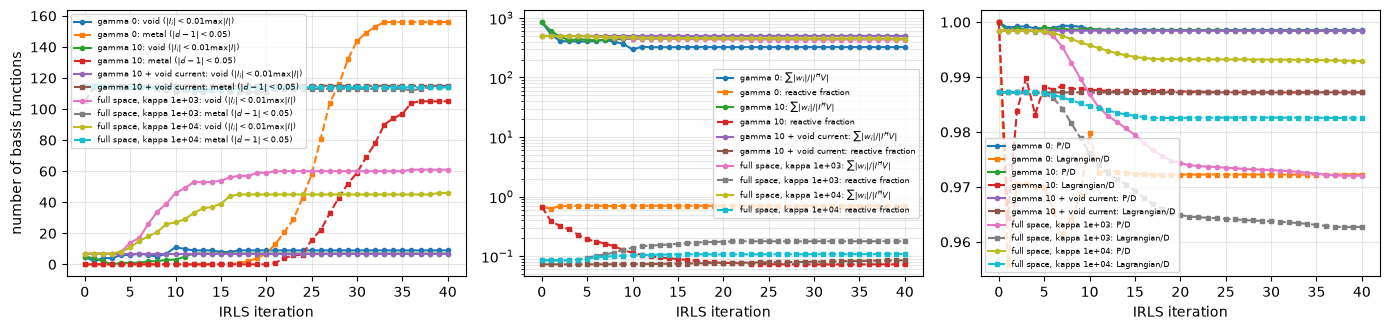

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for name, (x, hist) in results.items():
    it = [h["it"] for h in hist]
    axes[0].plot(it, [h["void"] for h in hist], 'o-', ms=3, label=rf"{name}: void ($|I_i| < 0.01 \max|I|$)")
    axes[0].plot(it, [h["metal"] for h in hist], 's--', ms=3, label=rf"{name}: metal ($|d - 1| < 0.05$)")
    axes[1].semilogy(it, [h["wSum"] for h in hist], 'o-', ms=3, label=rf"{name}: $\sum|w_i| / |I^H V|$")
    axes[1].plot(it, [h["reactive"] for h in hist], 's--', ms=3, label=rf"{name}: reactive fraction")
    axes[2].plot(it, [h["P"] for h in hist], 'o-', ms=3, label=rf"{name}: P/D")
    axes[2].plot(it, [h["Lag"] for h in hist], 's--', ms=3, label=rf"{name}: Lagrangian/D")
axes[0].set_ylabel('number of basis functions')
for ax in axes:
    ax.set_xlabel('IRLS iteration'); ax.legend(fontsize=6); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Pointwise inference and the complex material density

As in `nullSpaceMinField.ipynb`. The complex density $d_i = Z_s L_{ii} I_i / u_i$, with $u = V - Z_\mathrm{tot} I + Z_s L_{ii} I$, is 1 on metal and 0 where the
basis function is removed. The pointwise fits project it:
- the admittance form takes $\operatorname{clip}(\operatorname{Re} d, 0, 1)$;
- the impedance form projects the series impedance onto the passive ray.

The binary design with the largest scattered power over the rounding thresholds is kept.

In [12]:
dMin = 1e-6 # basis functions with d_i < dMin are removed in the realized structure
thsLog = np.logspace(-6, 0, 61)[:-1] # thresholds for binary rounding of d

def inferDimp(I):
    # impedance form: series impedance projected onto the passive ray, d = 1/(1 + t)
    nz = I != 0
    r = np.zeros(Ndes, dtype=complex)
    r[nz] = (Vinc - Ztot @ I)[nz]/I[nz]
    t = np.maximum(0, np.real(np.conj(Zs)*r)/(np.abs(Zs)**2*Ldiag))
    return np.where(nz, 1/(1 + t), 0.0)

def inferDadm(I):
    # admittance form: real part of the complex density, clipped
    return np.clip(complexDensity(I).real, 0, 1)

def realizedCurrent(d):
    # (Ztot + diag(Zs Lii (1/d - 1))) I = V on the kept basis functions, I = 0 elsewhere
    keep = d >= dMin
    I = np.zeros(Ndes, dtype=complex)
    Zd = Ztot + np.diag(Zs*Ldiag*(1/np.maximum(d, dMin) - 1))
    I[keep] = np.linalg.solve(Zd[np.ix_(keep, keep)], Vinc[keep])
    return I

def bestBinary(d):
    designs = [d > t for t in thsLog]
    Is = [realizedCurrent(k.astype(float)) for k in designs]
    Pb = np.array([evalObj(I) for I in Is])
    k = int(np.argmax(Pb))
    return dict(keep=designs[k], I=Is[k], P=Pb[k], th=thsLog[k])

print(f"full plate: max |d - 1| = {np.abs(complexDensity(Ifull) - 1).max():.1e}")
final = {"GCD x* (reference)": xs, **{f"power residual, {n}": r[0] for n, r in results.items()}}
inference = {}
for name, x in final.items():
    I = VtoI(x)
    d = complexDensity(I)
    inference[name] = dict(d=d, **{form: bestBinary(infer(I)) for form, infer in [("impedance form", inferDimp), ("admittance form", inferDadm)]})
    print(f"{name:20s}: |d| quantiles 50/90/max " + "/".join(f"{q:.1e}" for q in np.quantile(np.abs(d), [0.5, 0.9, 1.0]))
          + f", |d - 1| < 0.1: {np.count_nonzero(np.abs(d - 1) < 0.1):3d}, "
          + ", ".join(f"{form} P/D {inference[name][form]['P']/Qgcd.current_dual:.4f} ({inference[name][form]['P']:.3e} W, kept {inference[name][form]['keep'].sum()})"
                      for form in ["impedance form", "admittance form"]))

full plate: max |d - 1| = 1.2e-09
GCD x* (reference)  : |d| quantiles 50/90/max 1.2e-04/7.1e-04/1.1e-02, |d - 1| < 0.1:   0, impedance form P/D 0.0023 (4.123e-02 W, kept 225), admittance form P/D 0.0001 (1.164e-03 W, kept 101)
power residual, gamma 0: |d| quantiles 50/90/max 1.0e+00/1.0e+00/1.0e+00, |d - 1| < 0.1: 156, impedance form P/D 0.0023 (4.138e-02 W, kept 224), admittance form P/D 0.0033 (5.784e-02 W, kept 175)
power residual, gamma 10: |d| quantiles 50/90/max 5.7e-03/1.0e+00/1.4e+00, |d - 1| < 0.1: 110, impedance form P/D 0.0105 (1.855e-01 W, kept 199), admittance form P/D 0.0025 (4.349e-02 W, kept 174)


power residual, gamma 10 + void current: |d| quantiles 50/90/max 2.6e-03/1.0e+00/1.0e+00, |d - 1| < 0.1: 115, impedance form P/D 0.0105 (1.855e-01 W, kept 199), admittance form P/D 0.0025 (4.352e-02 W, kept 173)
power residual, full space, kappa 1e+03: |d| quantiles 50/90/max 6.8e-04/1.0e+00/1.0e+00, |d - 1| < 0.1: 114, impedance form P/D 0.0271 (4.816e-01 W, kept 174), admittance form P/D 0.0024 (4.330e-02 W, kept 152)
power residual, full space, kappa 1e+04: |d| quantiles 50/90/max 2.6e-03/1.0e+00/1.0e+00, |d - 1| < 0.1: 114, impedance form P/D 0.0200 (3.546e-01 W, kept 169), admittance form P/D 0.0024 (4.185e-02 W, kept 159)


### Relaxed designs (no rounding)

The structure with the relaxed density $d_i \in [0, 1]$ is solved directly in the admittance form, $(Z_\mathrm{tot} + \operatorname{diag}(Z_s L_{ii}(1/d_i - 1))) I = V$
(basis functions with $d_i < 10^{-6}$ removed). Two densities per current:
- $\operatorname{clip}(\operatorname{Re} d, 0, 1)$ of the complex density (admittance form);
- the passive projection of the series impedance (impedance form).

A density $0 < d < 1$ is a resistive sheet, so a relaxed design is not a copper structure. It shows what the inferred density achieves before
rounding.

In [13]:
def grayFraction(d):
    return np.mean((d > 0.05) & (d < 0.95))

relaxed = {}
for name, x in final.items():
    I = VtoI(x)
    dens = {"Re d clipped": inferDadm(I), "impedance form": inferDimp(I)}
    relaxed[name] = {k: dict(d=dk, P=evalObj(realizedCurrent(dk))) for k, dk in dens.items()}
    print(f"{name:42s}: dual current P/D {evalObj(I)/Qgcd.current_dual:.4f}; " + "; ".join(
        f"{k}: relaxed P/D {v['P']/Qgcd.current_dual:.4f} ({v['P']:.3e} W, gray {grayFraction(v['d']):.0%}), "
        f"binary {inference[name]['admittance form' if k == 'Re d clipped' else 'impedance form']['P']/Qgcd.current_dual:.4f}"
        for k, v in relaxed[name].items()))

GCD x* (reference)                        : dual current P/D 1.0000; Re d clipped: relaxed P/D 0.0000 (7.179e-04 W, gray 0%), binary 0.0001; impedance form: relaxed P/D 0.0026 (4.530e-02 W, gray 0%), binary 0.0023
power residual, gamma 0                   : dual current P/D 0.9985; Re d clipped: relaxed P/D 0.0027 (4.781e-02 W, gray 0%), binary 0.0033; impedance form: relaxed P/D 0.0024 (4.195e-02 W, gray 0%), binary 0.0023
power residual, gamma 10                  : dual current P/D 0.9984; Re d clipped: relaxed P/D 0.0025 (4.399e-02 W, gray 2%), binary 0.0025; impedance form: relaxed P/D 0.0025 (4.499e-02 W, gray 2%), binary 0.0105
power residual, gamma 10 + void current   : dual current P/D 0.9985; Re d clipped: relaxed P/D 0.0025 (4.395e-02 W, gray 0%), binary 0.0025; impedance form: relaxed P/D 0.0025 (4.499e-02 W, gray 0%), binary 0.0105
power residual, full space, kappa 1e+03   : dual current P/D 0.9721; Re d clipped: relaxed P/D 0.0025 (4.396e-02 W, gray 0%), binary 0.0024; imp

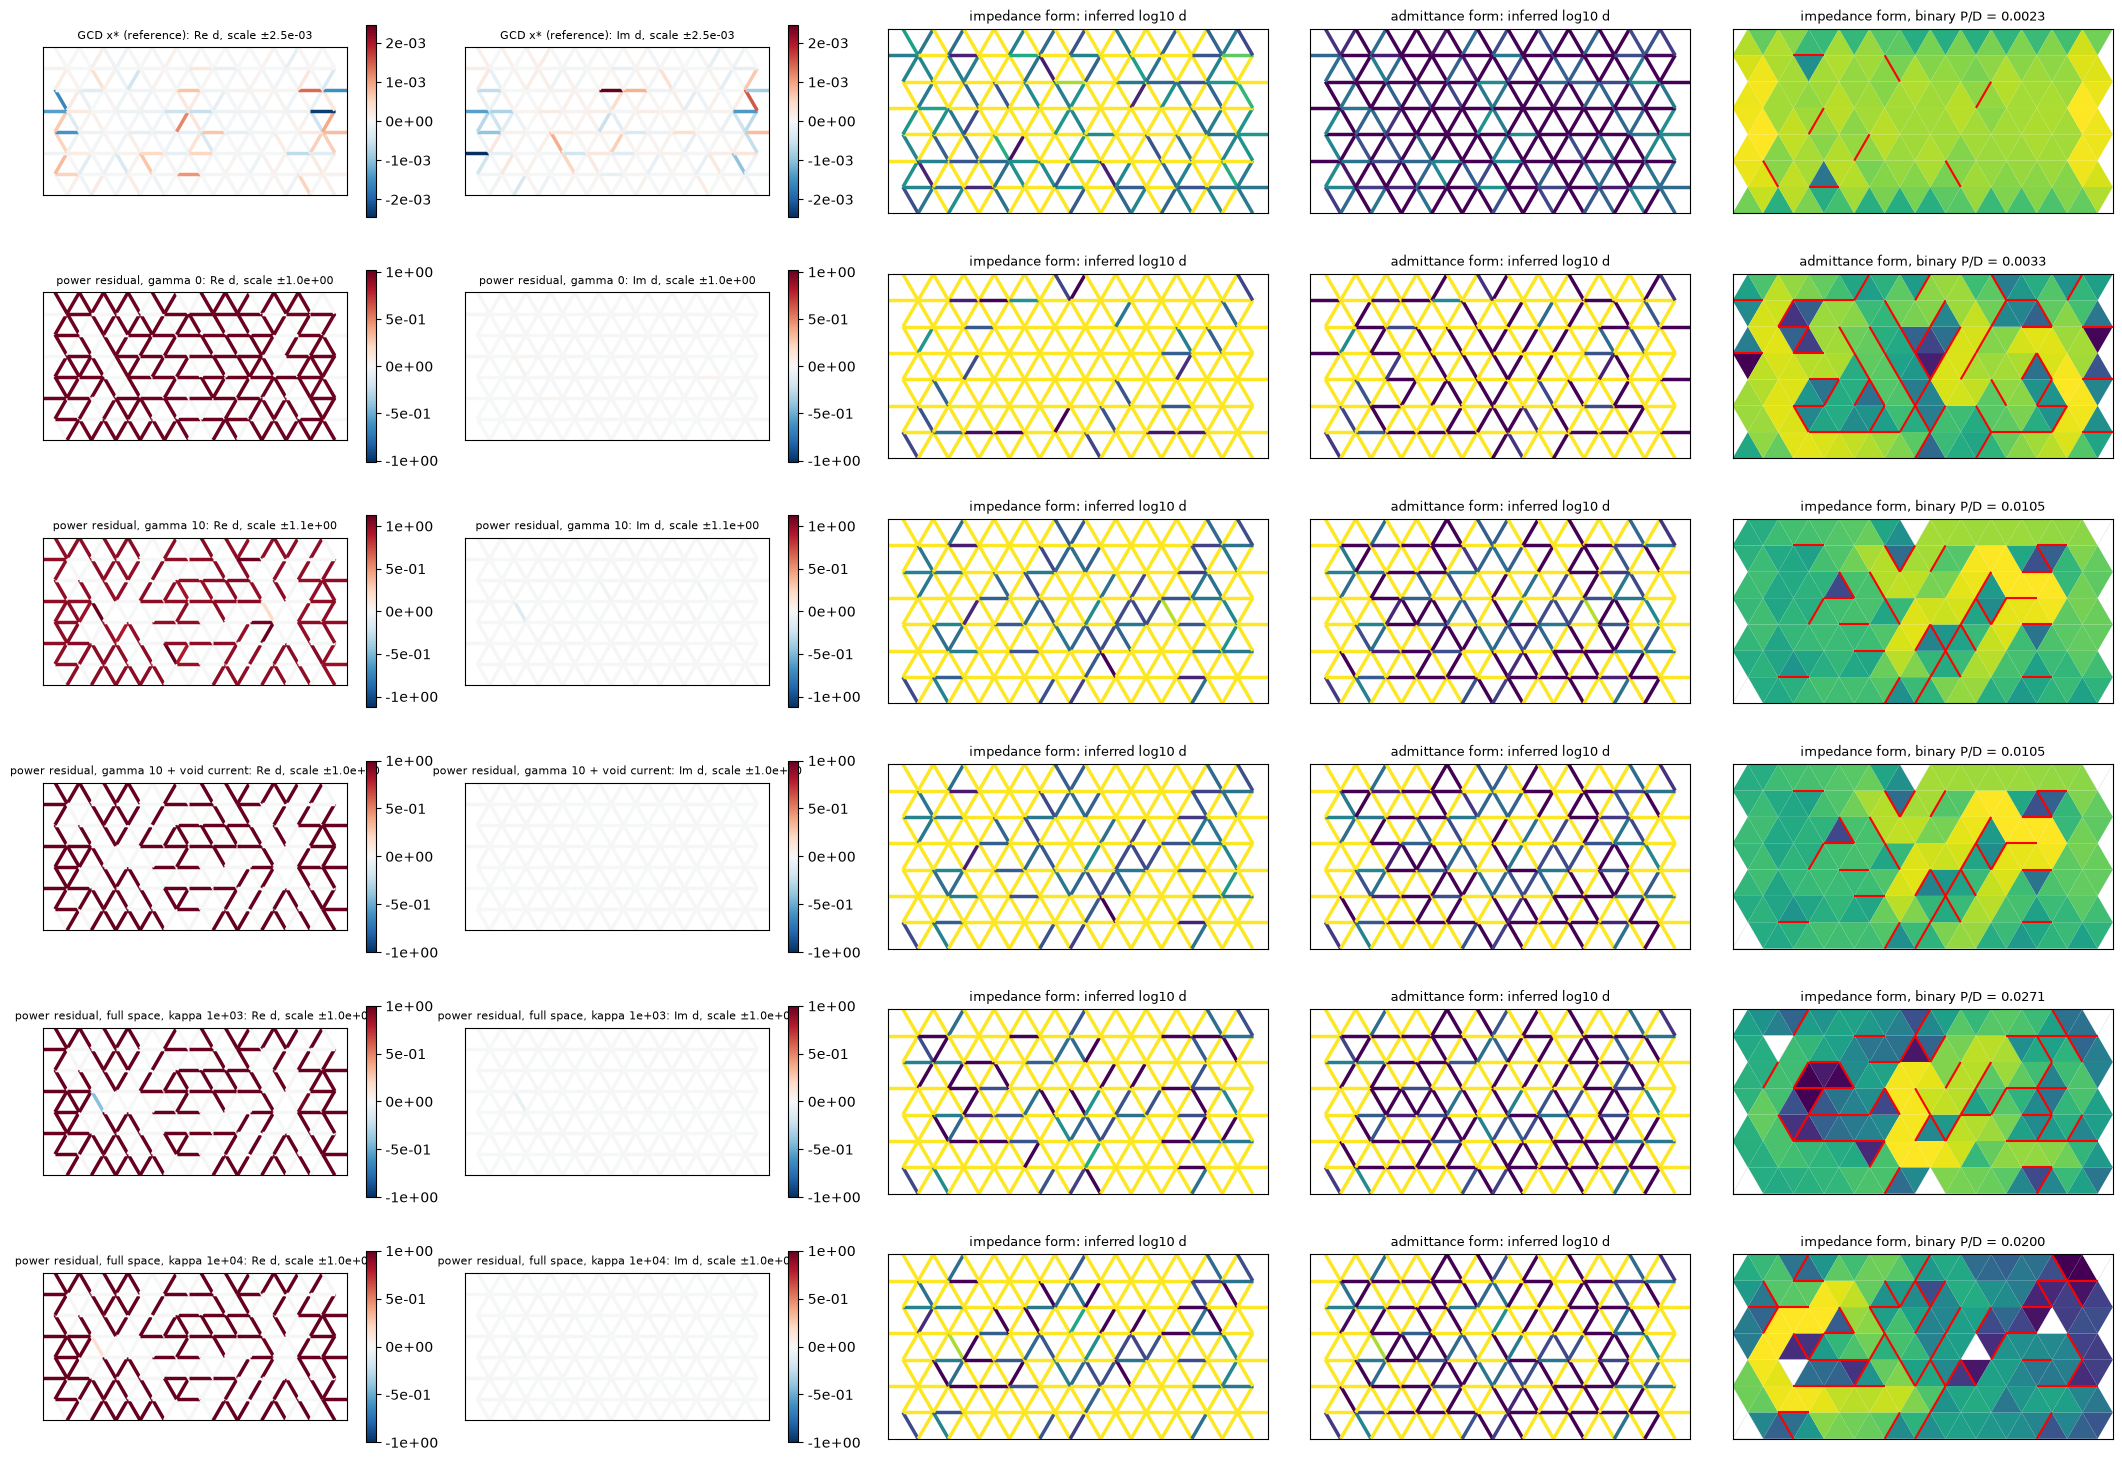

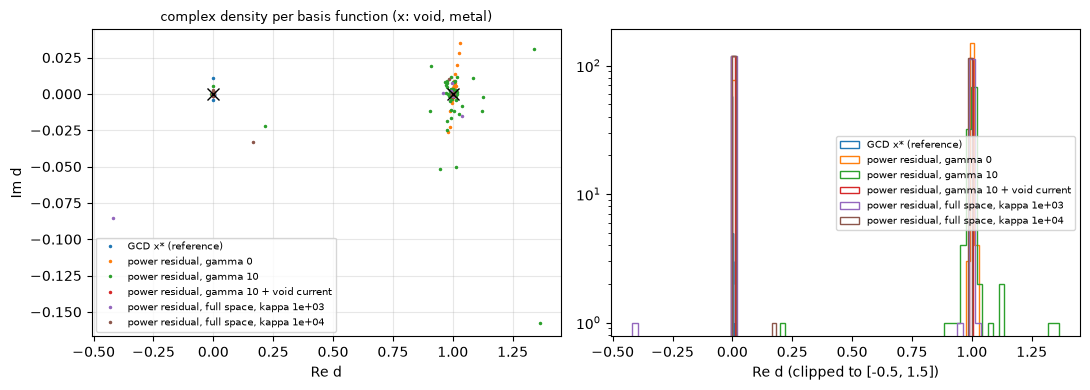

In [14]:
# final pointwise densities: real and imaginary part of the complex density, the inferred passive densities, and the binary design
names = list(inference)
fig, axes = plt.subplots(len(names), 5, figsize=(21, 2.5*len(names)))
for row, name in zip(axes, names):
    r = inference[name]
    plotComplexDensity(row[:2], r["d"], name)
    I = VtoI(final[name])
    for ax, form, infer in [(row[2], "impedance form", inferDimp), (row[3], "admittance form", inferDadm)]:
        lc = plotDensity(ax, infer(I), f"{form}: inferred log10 d")
    form = max(["impedance form", "admittance form"], key=lambda f: r[f]["P"])
    plotStructure(row[4], r[form]["keep"], r[form]["I"], f"{form}, binary P/D = {r[form]['P']/Qgcd.current_dual:.4f}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in names:
    d = inference[name]["d"]
    axes[0].plot(d.real, d.imag, '.', ms=3, label=name)
    axes[1].hist(np.clip(d.real, -0.5, 1.5), bins=60, histtype='step', label=name)
axes[0].plot([0, 1], [0, 0], 'kx', ms=8); axes[0].set_xlabel('Re d'); axes[0].set_ylabel('Im d'); axes[0].legend(fontsize=7)
axes[0].set_title('complex density per basis function (x: void, metal)', fontsize=9); axes[0].grid(True, alpha=0.3)
axes[1].set_yscale('log'); axes[1].set_xlabel('Re d (clipped to [-0.5, 1.5])'); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Conclusions

These are the numbers of this run. GCD is not exactly reproducible, so the counts and the inferred designs vary between runs; the binary designs
by a factor of 2–5 (the $\gamma = 10$ kernel design ranged from 0.7 % to 5.9 % of the bound).

**Setup.** At $\epsilon = 10^{-4}$ the kernel has dimension $K = 162$. The linearization of $w$ agrees with a finite difference to $2\times10^{-6}$.
Every Gauss–Newton step keeps the global power balance to $\|c\|/D \lesssim 10^{-3}$, except the last $\kappa = 10^4$ iterate ($2\times10^{-2}$).

**The complex density becomes binary.** $\operatorname{Re} d$ splits into clusters at 1 and near 0 with $\operatorname{Im} d \approx 0$. With $\gamma = 10$ the
off-ray (reactive) fraction of $\sum|w|$ drops from 0.68 to 0.07; with $\gamma = 0$ it stays at 0.70.

| current | metal | void | binary | Lagrangian / $D$ | $P/D$ of the current |
|---|---|---|---|---|---|
| kernel, $\gamma = 0$ | 156 | 9 | 165 | 0.972 | 0.999 |
| kernel, $\gamma = 10$ | 105 | 7 | 112 | 0.987 | 0.998 |
| kernel, void phase | 115 | 7 | 122 | 0.987 | 0.999 |
| full space, $\kappa = 10^3$ | 114 | 61 | 175 | 0.963 | 0.972 |
| full space, $\kappa = 10^4$ | 114 | 46 | 160 | 0.983 | 0.993 |

Metal means $|d_i - 1| < 0.05$, void means $|I_i| < 0.01\max|I|$.
- **Kernel limit.** In the kernel, at most about $K \approx 161$ basis functions can be binary (one complex condition each against $2K - 2$ real degrees
  of freedom), and $\gamma = 0$ reaches that.
- **Void currents.** The void phase cannot empty the $d \approx 0$ edges inside the kernel. Releasing the image part with the Lagrangian penalty
  $\kappa J/D$ does: 46–61 void edges, for 1.7–2.4 % more of the Lagrangian. Still, about half of the 118 edges in the void set keep their
  current, because the IRLS stalls at a local minimum once $\delta_I$ reaches its floor.

**Relaxed designs (no rounding).** Every relaxed design scatters 0.042–0.048 W, i.e. 0.24–0.27 % of the bound and about the full plate
(0.041 W). This holds both for $\operatorname{clip}(\operatorname{Re} d, 0, 1)$ and for the impedance-form density, and for the GCD current as well
as all IRLS currents. Practically no basis function is gray: the densities are already near-binary. The reason is the size of $Z_s$:
- **Small $d$ still conducts.** A relaxed edge with density $d$ adds the series impedance $Z_s L_{ii}(1/d - 1)$. For copper this stays small against the free-space
  impedance unless $d$ is very small (the rounding thresholds go down to $10^{-6}$ for this reason, as in `maxScatFixQ.ipynb`). The "void" edges of the IRLS currents sit at $|d| \sim 10^{-3}$ (median $|d|$ of $3\times10^{-3}$ to
  $7\times10^{-4}$), so in the relaxed structure they still act as metal, and it behaves like the full plate.
- **Small $d$ in the dual current means a large voltage drop.** In the dual current the same edges carry current at a voltage drop $|u_i|$
  about $10^3$ times the copper drop. That is consistent only with a large series impedance, which no density in $[0, 1]$ with $|d| \sim 10^{-3}$
  provides.

**Binary designs.** Rounding over the thresholds $t \in [10^{-6}, 1)$ removes the low-density edges and is therefore *better* than the relaxed
design:

| current | best binary design |
|---|---|
| GCD $x^\star$ | 0.23 % |
| kernel, $\gamma = 0$ | 0.33 % |
| kernel, $\gamma = 10$ | 1.05 % |
| kernel, void phase | 1.05 % |
| full space, $\kappa = 10^3$ | **2.71 %** (0.48 W) |
| full space, $\kappa = 10^4$ | 2.00 % |

The full-space currents, which make more edges truly void, give the best designs, about $10\times$ the GCD $x^\star$.

**Bottom line.**
- **Metric.** The power-residual metric makes the density binary.
- **Image part.** Releasing the image part lets the void currents go to zero.
- **Inference.** The realized designs follow the number of truly void edges, not the binarity of $d$. Without rounding, the copper density
  scale (only a very small $d$ makes an edge electrically open) turns every relaxed design into the full plate.

The next step is to impose $I_i = 0$ exactly on settled void edges.